# 01 · Data Exploration

**Project:** Beyond Optimization: Testing the Structural Validity of Portfolio Models
**Phase 1, Task 1.A, Part A** (data and hygiene)

## Research purpose
Before any portfolio model is built, the data must be documented and screened. Every later result depends on these choices, so they are fixed in one configuration cell and written to disk with the download date for reproducibility.

## What this notebook does NOT do
- It makes **no performance claims** and builds **no portfolios**.
- It does not tune any choice after looking at the output.
- The five ETFs are a small teaching universe for Phase 1. They are **not** the final 10 to 15 ETF study universe, which needs its own selection and survivorship write-up.

## Data source and licensing
Prices come from Yahoo Finance through the `yfinance` package, which wraps Yahoo's public data. Use it for personal research only, expect occasional gaps or revisions, and keep the raw download so results can be reproduced.

## Sections
1. Imports and versions
2. Fixed research configuration
3. Download and archive raw data
4. Data quality report
5. Sample alignment
6. Return calculation
7. Extreme-observation screen (flag, do not delete)
8. Descriptive statistics
9. Visual exploration
10. Save processed data and metadata
11. Interpretation prompts and sample limitations

## 1. Imports and versions
Recording library versions matters because `yfinance` and `pandas` change behaviour between releases.

In [1]:
import json
import platform
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import scipy.stats as st
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid")

VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "yfinance": getattr(yf, "__version__", "unknown"),
}
for name, version in VERSIONS.items():
    print(f"{name:<11}{version}")

python     3.14.2
numpy      2.5.4
pandas     3.1.1
scipy      1.18.1
matplotlib 3.11.2
seaborn    0.13.2
yfinance   1.8.0


## 2. Fixed research configuration
Every choice is made **here, before looking at any data**, and not changed afterwards.

- `END` is exclusive in `yfinance`, so `2026-01-01` includes all of 2025.
- **Simple versus log returns.** Portfolio return is a weighted sum of *simple* asset returns across assets, R<sub>p</sub> = wᵀR, which is why simple returns are the default for portfolio work. Log returns add across *time* but not across assets. Write one sentence below justifying whichever you keep.

In [2]:
TICKERS = {
    "SPY": "US large-cap equities",
    "EFA": "Developed-market international equities",
    "AGG": "US investment-grade bonds",
    "GLD": "Gold (commodity)",
    "VNQ": "US real estate (REITs)",
}
START = "2012-01-01"
END = "2026-01-01"            # exclusive in yfinance: includes 31 Dec 2025
RETURN_TYPE = "simple"        # "simple" or "log"
TRADING_DAYS = 252            # used only for annualising descriptive statistics
OUTLIER_Z = 5.0               # |z| above this is FLAGGED, never removed
ROLL_VOL_WINDOW = 63          # about 3 months of trading days
ROLL_CORR_WINDOW = 252        # about 1 year
PAIR = ("SPY", "AGG")         # pair used for the rolling-correlation plot

DATA_ROOT = Path("..") / "data"   # notebooks/ sits one level below the project root
RAW_DIR = DATA_ROOT / "raw"
PROC_DIR = DATA_ROOT / "processed"
FIG_DIR = Path("..") / "results" / "figures"
for d in (RAW_DIR, PROC_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Your one-sentence justification for the return type:
RETURN_TYPE_NOTE = "TODO: write your justification here"

## 3. Download and archive raw data
`auto_adjust=True` is set **explicitly** because its default has changed between `yfinance` versions. With it on, `Close` is adjusted for splits and dividends, which matters because total return, not price return, is what an investor earns. Confirm this against the documentation for your installed version.

In [3]:
DOWNLOAD_TS = datetime.now(timezone.utc)
tickers = list(TICKERS)

raw = yf.download(tickers, start=START, end=END, auto_adjust=True, progress=False)
if raw is None or raw.empty:
    raise RuntimeError("yfinance returned no data. Check your internet connection and ticker symbols, then rerun.")

# With several tickers the columns are a MultiIndex: (field, ticker).
prices = raw["Close"].copy()
missing_cols = [t for t in tickers if t not in prices.columns]
if missing_cols:
    raise RuntimeError(f"No data returned for: {missing_cols}")

prices = prices[tickers]
prices.index = pd.DatetimeIndex(prices.index).tz_localize(None)
prices.index.name = "Date"
prices = prices.sort_index()

# Archive the untouched download. To reload: pd.read_csv(path, header=[0, 1], index_col=0, parse_dates=True)
raw_path = RAW_DIR / f"yfinance_raw_{DOWNLOAD_TS:%Y%m%d}.csv"
raw.to_csv(raw_path)
print(f"Downloaded {prices.shape[0]} rows x {prices.shape[1]} tickers")
print(f"Raw data archived to: {raw_path}")
prices.head()

Downloaded 3520 rows x 5 tickers
Raw data archived to: ..\data\raw\yfinance_raw_20261111.csv


Ticker,SPY,EFA,AGG,GLD,VNQ
Date,,,,,
2012-01-03,98.8116,32.8643,73.4184,155.9200,32.6946
2012-01-04,98.9666,32.6705,73.3183,156.7100,32.1357
2012-01-05,99.2302,32.1861,73.4184,157.7800,32.4375
2012-01-06,98.9744,31.7468,73.4784,157.2000,32.3313
2012-01-09,99.2147,31.8696,73.4184,156.5000,32.2195


## 4. Data quality report
Checks for the problems that quietly corrupt estimates: missing data, non-positive prices, duplicate dates and long calendar gaps.
Normal calendar gaps are 1 to 4 days (weekends and holiday weekends). Anything longer deserves an explanation.

In [4]:
report = pd.DataFrame({
    "first_valid": prices.apply(lambda s: s.first_valid_index()),
    "last_valid": prices.apply(lambda s: s.last_valid_index()),
    "n_obs": prices.notna().sum(),
    "n_missing": prices.isna().sum(),
    "min_price": prices.min(),
    "n_nonpositive": (prices <= 0).sum(),
})
report["pct_missing"] = 100 * report["n_missing"] / len(prices)
report["first_valid"] = pd.to_datetime(report["first_valid"]).dt.date
report["last_valid"] = pd.to_datetime(report["last_valid"]).dt.date
display(report)

# Missing values AFTER an asset's first valid date are real data gaps, not just a late inception.
internal_missing = prices.apply(lambda s: int(s.loc[s.first_valid_index():].isna().sum()))
print("\nMissing values after each asset's first valid date:")
print(internal_missing.to_string())

print("\nDuplicate dates:", int(prices.index.duplicated().sum()))
print("Index strictly increasing:", bool(prices.index.is_monotonic_increasing))

gap_days = prices.index.to_series().diff().dt.days
print("\nFive largest calendar gaps (days, ending on the date shown):")
print(gap_days.sort_values(ascending=False).head(5).to_string())

,first_valid,last_valid,n_obs,n_missing,min_price,n_nonpositive,pct_missing
Ticker,,,,,,,
SPY,2012-01-03,2025-12-31,3520,0,98.8116,0,0.0000
EFA,2012-01-03,2025-12-31,3520,0,30.0675,0,0.0000
AGG,2012-01-03,2025-12-31,3520,0,73.0475,0,0.0000
GLD,2012-01-03,2025-12-31,3520,0,100.5000,0,0.0000
VNQ,2012-01-03,2025-12-31,3520,0,32.1357,0,0.0000



Missing values after each asset's first valid date:
Ticker
SPY    0
EFA    0
AGG    0
GLD    0
VNQ    0

Duplicate dates: 0
Index strictly increasing: True

Five largest calendar gaps (days, ending on the date shown):
Date
2012-10-31   5.0000
2015-07-06   4.0000
2017-12-26   4.0000
2016-07-05   4.0000
2019-04-22   4.0000


## 5. Sample alignment
Covariance estimation needs all assets observed on the same dates, so the sample is cut to the dates where **every** asset has a price.

No forward-filling is used. Filling gaps with the previous price manufactures zero returns, which understate volatility and distort correlations.

In [5]:
n_before = len(prices)
prices_aligned = prices.dropna(how="any")

common_start = prices_aligned.index[0]
common_end = prices_aligned.index[-1]
binding_ticker = prices.apply(lambda s: s.first_valid_index()).idxmax()
rows_dropped = n_before - len(prices_aligned)

print(f"Rows before alignment : {n_before}")
print(f"Rows after alignment  : {len(prices_aligned)}")
print(f"Rows dropped          : {rows_dropped}")
print(f"Common sample         : {common_start.date()} to {common_end.date()}")
print(f"Binding asset (latest first valid date): {binding_ticker}")

Rows before alignment : 3520
Rows after alignment  : 3520
Rows dropped          : 0
Common sample         : 2012-01-03 to 2025-12-31
Binding asset (latest first valid date): SPY


## 6. Return calculation
- Simple return: r<sub>t</sub> = P<sub>t</sub>/P<sub>t-1</sub> − 1
- Log return: r<sub>t</sub> = ln(P<sub>t</sub>/P<sub>t-1</sub>)

Both are computed. The one in `RETURN_TYPE` is used downstream.
A high share of exactly zero returns can signal stale prices.

In [6]:
if RETURN_TYPE not in ("simple", "log"):
    raise ValueError("RETURN_TYPE must be 'simple' or 'log'")

simple_ret = prices_aligned.pct_change().dropna()
log_ret = np.log(prices_aligned).diff().dropna()
returns = (simple_ret if RETURN_TYPE == "simple" else log_ret).copy()
returns.index.name = "Date"

print(f"Return type used: {RETURN_TYPE}")
print(f"Observations T = {returns.shape[0]}, assets N = {returns.shape[1]}, T/N = {returns.shape[0] / returns.shape[1]:.0f}")
print("\nShare of exactly-zero daily returns (%):")
print((100 * (returns == 0).mean()).round(2).to_string())

Return type used: simple
Observations T = 3519, assets N = 5, T/N = 704

Share of exactly-zero daily returns (%):
Ticker
SPY   0.3100
EFA   0.7400
AGG   1.4500
GLD   0.3100
VNQ   0.4800


## 7. Extreme-observation screen (flag, do not delete)
Extreme days are real market events, not errors. Deleting them would remove exactly the tail behaviour the project studies. They are **flagged and listed**, and any later decision to treat them differently must be made explicitly and justified.

In [7]:
long = returns.melt(ignore_index=False, var_name="ticker", value_name="ret")
long["z"] = long.groupby("ticker")["ret"].transform(lambda s: (s - s.mean()) / s.std())
long["abs_ret"] = long["ret"].abs()

flag_counts = (long["z"].abs() > OUTLIER_Z).groupby(long["ticker"]).sum().astype(int)
print(f"Days with |z| > {OUTLIER_Z} (per asset):")
print(flag_counts.to_string())

print("\nTen largest absolute daily returns:")
display(long.sort_values("abs_ret", ascending=False).head(10).drop(columns="abs_ret"))

Days with |z| > 5.0 (per asset):
ticker
AGG    10
EFA    12
GLD     6
SPY    12
VNQ    12

Ten largest absolute daily returns:


,ticker,ret,z
Date,,,
2020-03-16,VNQ,-0.1773,-14.6791
2020-03-12,EFA,-0.1099,-10.4822
2020-03-16,SPY,-0.1094,-10.4780
2025-04-09,SPY,0.1050,9.9439
2020-03-16,EFA,-0.1032,-9.8445
2020-03-12,VNQ,-0.1013,-8.4006
2020-03-12,SPY,-0.0957,-9.1689
2020-03-18,VNQ,-0.0951,-7.8902
2020-03-24,SPY,0.0906,8.5710


## 8. Descriptive statistics
These are **descriptive**, not formal tests. The Jarque-Bera statistic is shown only to preview Test 5. With thousands of daily observations it rejects normality almost always, so the p-value alone says little about *how much* the Gaussian assumption matters. Formal treatment comes later.

In [8]:
desc = pd.DataFrame({
    "ann_mean": returns.mean() * TRADING_DAYS,
    "ann_vol": returns.std() * np.sqrt(TRADING_DAYS),
    "skew": returns.skew(),
    "excess_kurtosis": returns.kurt(),
    "min_daily": returns.min(),
    "max_daily": returns.max(),
})
jb = {c: st.jarque_bera(returns[c].to_numpy()) for c in returns.columns}
desc["JB_stat"] = pd.Series({c: r.statistic for c, r in jb.items()})
desc["JB_pvalue"] = pd.Series({c: r.pvalue for c, r in jb.items()})
display(desc)

,ann_mean,ann_vol,skew,excess_kurtosis,min_daily,max_daily,JB_stat,JB_pvalue
Ticker,,,,,,,,
SPY,0.1517,0.1667,-0.3189,14.7167,-0.1094,0.1050,"31,718.4153",0.0000
EFA,0.0897,0.1670,-0.7345,12.2212,-0.1099,0.0847,"22,147.4904",0.0000
AGG,0.0211,0.0485,-1.0583,20.9069,-0.0400,0.0237,"64,553.7179",0.0000
GLD,0.0786,0.1537,-0.4063,4.9633,-0.0878,0.0490,"3,696.0573",0.0000
VNQ,0.0879,0.1921,-1.0464,20.6030,-0.1773,0.0900,"62,694.4167",0.0000


## 9. Visual exploration
Three views that preview later tests: growth paths, time-varying volatility and time-varying correlation.

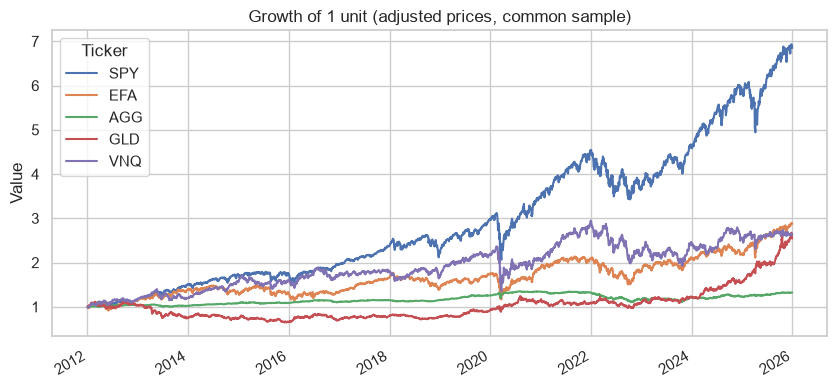

In [9]:
growth = prices_aligned / prices_aligned.iloc[0]
fig, ax = plt.subplots(figsize=(10, 4.5))
growth.plot(ax=ax)
ax.set_title("Growth of 1 unit (adjusted prices, common sample)")
ax.set_ylabel("Value")
ax.set_xlabel("")
fig.savefig(FIG_DIR / "01_growth_of_one_unit.png", dpi=150, bbox_inches="tight")
plt.show()

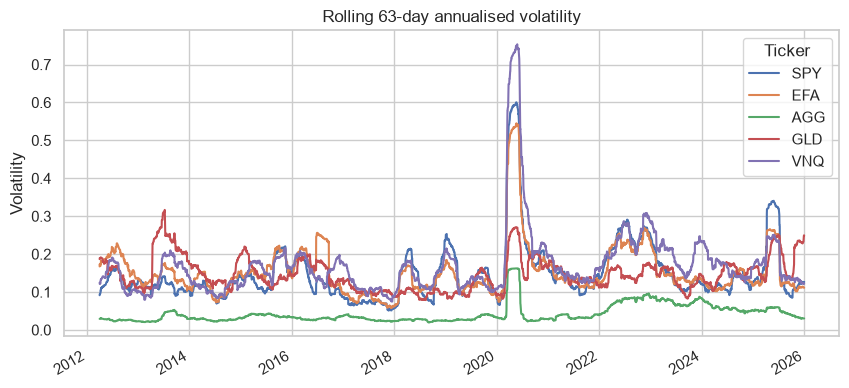

In [10]:
roll_vol = returns.rolling(ROLL_VOL_WINDOW).std() * np.sqrt(TRADING_DAYS)
fig, ax = plt.subplots(figsize=(10, 4.5))
roll_vol.plot(ax=ax)
ax.set_title(f"Rolling {ROLL_VOL_WINDOW}-day annualised volatility")
ax.set_ylabel("Volatility")
ax.set_xlabel("")
fig.savefig(FIG_DIR / "01_rolling_volatility.png", dpi=150, bbox_inches="tight")
plt.show()

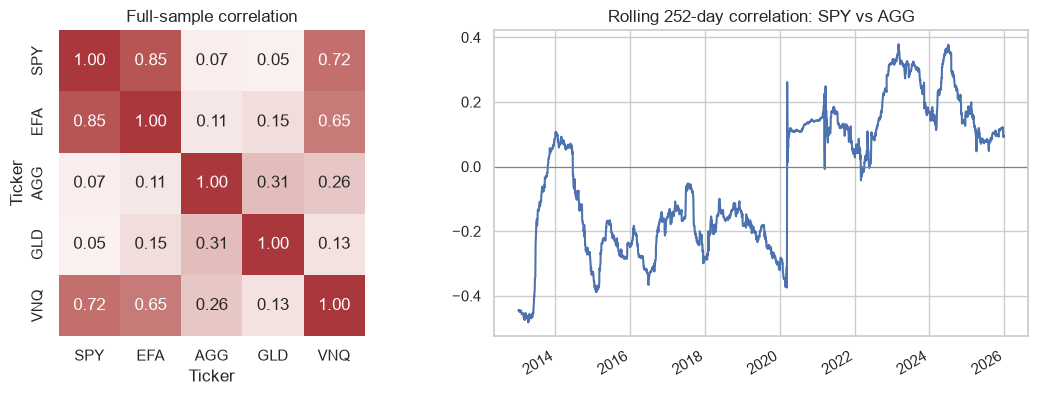

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})

sns.heatmap(returns.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, cbar=False, ax=axes[0])
axes[0].set_title("Full-sample correlation")

if all(t in returns.columns for t in PAIR):
    roll_corr = returns[PAIR[0]].rolling(ROLL_CORR_WINDOW).corr(returns[PAIR[1]])
    roll_corr.plot(ax=axes[1])
    axes[1].axhline(0, color="grey", lw=0.8)
    axes[1].set_title(f"Rolling {ROLL_CORR_WINDOW}-day correlation: {PAIR[0]} vs {PAIR[1]}")
    axes[1].set_xlabel("")
else:
    axes[1].axis("off")

fig.savefig(FIG_DIR / "01_correlation_views.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Save processed data and metadata
The metadata file records every choice and the environment, so the dataset can be reproduced and audited.

In [12]:
returns_path = PROC_DIR / f"returns_{RETURN_TYPE}_daily.csv"
prices_path = PROC_DIR / "prices_adjusted_aligned.csv"
meta_path = PROC_DIR / "data_metadata.json"

returns.to_csv(returns_path)
prices_aligned.to_csv(prices_path)

metadata = {
    "download_timestamp_utc": DOWNLOAD_TS.isoformat(),
    "source": "Yahoo Finance via yfinance (auto_adjust=True)",
    "tickers": TICKERS,
    "requested_window": {"start": START, "end_exclusive": END},
    "common_sample": {"start": str(common_start.date()), "end": str(common_end.date())},
    "binding_ticker": str(binding_ticker),
    "rows_before_alignment": int(n_before),
    "rows_after_alignment": int(len(prices_aligned)),
    "rows_dropped": int(rows_dropped),
    "return_type": RETURN_TYPE,
    "return_type_note": RETURN_TYPE_NOTE,
    "n_return_observations": int(returns.shape[0]),
    "n_assets": int(returns.shape[1]),
    "outlier_threshold_abs_z": OUTLIER_Z,
    "outlier_days_flagged_per_asset": {k: int(v) for k, v in flag_counts.items()},
    "outliers_removed": False,
    "missing_values_filled": False,
    "raw_file": str(raw_path),
    "library_versions": VERSIONS,
}
meta_path.write_text(json.dumps(metadata, indent=2, default=str))

# Round-trip check: what we saved must equal what we hold in memory.
reloaded = pd.read_csv(returns_path, index_col="Date", parse_dates=True)
assert reloaded.shape == returns.shape and np.allclose(reloaded.to_numpy(), returns.to_numpy())
print("Saved and verified:")
for p in (raw_path, prices_path, returns_path, meta_path):
    print("  ", p)

Saved and verified:
   ..\data\raw\yfinance_raw_20261111.csv
   ..\data\processed\prices_adjusted_aligned.csv
   ..\data\processed\returns_simple_daily.csv
   ..\data\processed\data_metadata.json


## 11. Interpretation prompts and sample limitations

Answer these **in your own words** (a few sentences each) before moving to notebook 02. Plots without interpretation do not count as research.

1. Which ETF limits the common sample start, and what does that cost you in observations and in regimes covered?
2. Skewness and excess kurtosis are reported above. What do they say about the Gaussian assumption, and why can a tiny Jarque-Bera p-value be uninformative on its own?
3. Look at the rolling-volatility plot. Describe the pattern and explain why it matters for treating Σ as a single constant matrix.
4. Look at the rolling correlation. Is one full-sample correlation a defensible summary of that relationship? What would that imply for GMV weights estimated at different dates?
5. Why were extreme days flagged and not deleted?
6. These five ETFs were picked **today** because they are large and still exist. What bias does that introduce (survivorship and selection), and in which direction might it push the results?
7. What does the ratio T/N tell you about how reliable a sample covariance matrix is here, and how would your answer change with 100 assets?

### Sample limitations (complete this list yourself)
- Single realisation of history: one sample path, not a repeated experiment.
- Selection of ETFs made with hindsight.
- Adjusted prices depend on Yahoo's adjustment methodology and can be revised.
- *Add at least two more limitations you can justify from your own output.*